# Phase 12 — Ablation Study

**Notebook:** `11_ablation.ipynb`
**Project:** Physics-Informed GAT for Diabetic Foot Plantar Thermography (dual-branch architecture)

---

## 🔒 TEST SET ACCESS — SECOND AND FINAL TIME IN THIS PROJECT 🔒

This notebook is the **second and last** place in the entire project that `test_loader` is
touched. The first access was Phase 11 (`10_evaluation.ipynb`)'s primary-model evaluation.

This is a deliberate, standard exception for ablation studies: a **single, fair, one-pass**
comparison of 9 architectural variants on the same held-out set, reported together in the
paper. It is **not** license to iteratively retune any individual configuration based on its
own test result — every config is trained once (or reloaded, for the already-trained primary),
evaluated once on val for its own threshold, and evaluated once on test, all in this one run.

**After this notebook, no further test-set access should occur for the rest of this project.**

---

### What this notebook does, in order

1. Setup — seed, device, dataloaders, class weights, loss (identical to Phase 10).
2. Define the 9-config ablation matrix.
3. Train the 8 new configs (identical hyperparameters to Phase 10's primary run).
4. Reload the primary config's Phase 10 checkpoint (not retrained).
5. Per-config: own val-optimal threshold, fresh MC-Dropout test pass (T=30), foot- and
   subject-level metrics.
6. Bootstrap 95% CIs on subject-level test ROC-AUC (paired resampling across all 9 configs).
7. Full ranked results table.
8. Comparison plots (ROC-AUC with CIs; parameter count).
9. Qualitative summary (left for deliberate review of the actual numbers).
10. Save results.
11. Final summary + repeated test-set notice.

## Section 1 — Setup

Seed everything, resolve the project root, print the test-set-access notice, build the real
dataloaders (`train_loader`/`val_loader`/`test_loader` — this is only the **second** notebook
in the whole project allowed to build/use `test_loader`), recompute the same DM/Control class
weights Phase 10 used (from `patient_split.csv`'s train rows), and build the identical
`BCEWithLogitsLoss(pos_weight=weight_DM)` criterion. Everything here mirrors
`09_training.ipynb` Section 1 exactly, so the 8 new configs trained below are trained under
*identical* conditions to the primary config, and any performance difference in the final
table reflects the architecture change, not a training-setup difference.

In [1]:
import sys
from pathlib import Path

# --- Project root on sys.path, so `from src...` imports work regardless of the notebook's
#     working directory (VS Code sometimes launches the kernel from a different cwd). ---
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    for parent in Path.cwd().parents:
        if (parent / "src").exists():
            PROJECT_ROOT = parent
            break
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root resolved to: {PROJECT_ROOT}")

Project root resolved to: c:\workstation\3RD YEAR\Diabetic_Foot


In [2]:
import json

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
)

from src.dataset import build_dataloaders, load_normalization_stats
from src.train import build_model, train_model, evaluate
from src.mc_dropout import mc_dropout_predict

torch.manual_seed(42)

In [3]:
TEST_SET_NOTICE = (
    "This notebook (11_ablation.ipynb) touches the test set for the SECOND and FINAL time in\n"
    "this entire project. The first access was Phase 11's (10_evaluation.ipynb) primary-model\n"
    "evaluation. This is a deliberate, standard exception for ablation studies -- a single,\n"
    "fair, one-pass comparison of 9 architectural variants on the same held-out set, reported\n"
    "together in the paper.\n\n"
    "This is NOT license to iteratively retune any individual configuration based on its own\n"
    "test result. After this notebook, no further test-set access should occur for the rest\n"
    "of this project."
)

print("=" * 78)
print("=== TEST SET ACCESS NOTICE " + "=" * 50)
print("=" * 78)
print(TEST_SET_NOTICE)
print("=" * 78)

=== TEST SET ACCESS NOTICE ==================================================
This notebook (11_ablation.ipynb) touches the test set for the SECOND and FINAL time in
this entire project. The first access was Phase 11's (10_evaluation.ipynb) primary-model
evaluation. This is a deliberate, standard exception for ablation studies -- a single,
fair, one-pass comparison of 9 architectural variants on the same held-out set, reported
together in the paper.

This is NOT license to iteratively retune any individual configuration based on its own
test result. After this notebook, no further test-set access should occur for the rest
of this project.


In [4]:
print("=== SECTION 1: Setup ===")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"PROCESSED_DIR  = {PROCESSED_DIR}")
print(f"CHECKPOINT_DIR = {CHECKPOINT_DIR}")
print(f"RESULTS_DIR    = {RESULTS_DIR}")

=== SECTION 1: Setup ===
Device: cuda
PROCESSED_DIR  = c:\workstation\3RD YEAR\Diabetic_Foot\data\processed
CHECKPOINT_DIR = c:\workstation\3RD YEAR\Diabetic_Foot\checkpoints
RESULTS_DIR    = c:\workstation\3RD YEAR\Diabetic_Foot\results


In [5]:
# --- Normalization stats + all three dataloaders. This is only the SECOND notebook in the
#     whole project allowed to build/use test_loader (see notice above). ---
normalization_stats = load_normalization_stats(PROCESSED_DIR)
loaders = build_dataloaders(PROCESSED_DIR, normalization_stats, batch_size=16)

train_loader = loaders["train"]
val_loader = loaders["val"]
test_loader = loaders["test"]  # <-- second and final use of test_loader in this project

train_dataset = loaders["train_dataset"]
val_dataset = loaders["val_dataset"]
test_dataset = loaders["test_dataset"]

print(f"Dataset sizes -> train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")
assert len(train_dataset) == 232, f"Expected 232 train rows, found {len(train_dataset)}"
assert len(val_dataset) == 50, f"Expected 50 val rows, found {len(val_dataset)}"
assert len(test_dataset) == 52, f"Expected 52 test rows, found {len(test_dataset)}"
print("PASS: dataset sizes match the expected 232/50/52 split.")

Dataset sizes -> train: 232, val: 50, test: 52
PASS: dataset sizes match the expected 232/50/52 split.


In [6]:
# --- Class weights, recomputed fresh from patient_split.csv (train split only) -- IDENTICAL
#     procedure to Phase 10 (09_training.ipynb Section 1), so the loss used to train the 8 new
#     ablation configs is the exact same loss the primary config was trained with. ---
patient_split_df = pd.read_csv(PROCESSED_DIR / "patient_split.csv")
train_subjects_df = patient_split_df.loc[patient_split_df["split"] == "train"]

group_counts = train_subjects_df["Group"].value_counts()
n_train = len(train_subjects_df)
count_dm = int(group_counts.get("DM", 0))
count_control = int(group_counts.get("Control", 0))

weight_dm = n_train / (2 * count_dm)
weight_control = n_train / (2 * count_control)

print(f"Train subjects: {n_train}  (DM={count_dm}, Control={count_control})")
print(f"Inverse-frequency weight_DM      = {weight_dm:.4f}")
print(f"Inverse-frequency weight_Control = {weight_control:.4f}")
print("Using weight_DM as pos_weight (downweights the majority DM class) -- identical to Phase 10.")

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight_dm, dtype=torch.float32).to(device))
print(f"\ncriterion = BCEWithLogitsLoss(pos_weight={weight_dm:.4f})")

Train subjects: 116  (DM=85, Control=31)
Inverse-frequency weight_DM      = 0.6824
Inverse-frequency weight_Control = 1.8710
Using weight_DM as pos_weight (downweights the majority DM class) -- identical to Phase 10.

criterion = BCEWithLogitsLoss(pos_weight=0.6824)


## Section 2 — Ablation Configuration Matrix

9 configurations spanning the dual-branch architecture and both single-branch ablations,
crossed with the two graph topologies (base 4-cycle vs. diagonal-augmented, from Phase 6) and
the three image sources (colormap / raw / relative, from Phase 4). `dual_colormap_base` is the
already-trained Phase 10 primary configuration and is **not** retrained in Section 3 — it is
reloaded from its Phase 10 checkpoint in Section 4.

In [7]:
print("=== SECTION 2: Ablation Configuration Matrix ===")

ABLATION_CONFIGS = [
    {"name": "dual_colormap_base",  "use_graph_branch": True,  "use_image_branch": True,
     "graph_topology": "base", "image_key": "colormap_image", "image_in_channels": 3},
    {"name": "dual_raw_base",       "use_graph_branch": True,  "use_image_branch": True,
     "graph_topology": "base", "image_key": "raw_image",      "image_in_channels": 1},
    {"name": "dual_relative_base",  "use_graph_branch": True,  "use_image_branch": True,
     "graph_topology": "base", "image_key": "relative_image", "image_in_channels": 1},
    {"name": "dual_colormap_diag",  "use_graph_branch": True,  "use_image_branch": True,
     "graph_topology": "diag", "image_key": "colormap_image", "image_in_channels": 3},
    {"name": "graph_only_base",     "use_graph_branch": True,  "use_image_branch": False,
     "graph_topology": "base", "image_key": None,             "image_in_channels": None},
    {"name": "graph_only_diag",     "use_graph_branch": True,  "use_image_branch": False,
     "graph_topology": "diag", "image_key": None,             "image_in_channels": None},
    {"name": "image_only_colormap", "use_graph_branch": False, "use_image_branch": True,
     "graph_topology": "base", "image_key": "colormap_image", "image_in_channels": 3},
    {"name": "image_only_raw",      "use_graph_branch": False, "use_image_branch": True,
     "graph_topology": "base", "image_key": "raw_image",      "image_in_channels": 1},
    {"name": "image_only_relative", "use_graph_branch": False, "use_image_branch": True,
     "graph_topology": "base", "image_key": "relative_image", "image_in_channels": 1},
]
PRIMARY_CONFIG_NAME = "dual_colormap_base"

assert len(ABLATION_CONFIGS) == 9, f"Expected 9 configs, found {len(ABLATION_CONFIGS)}"
expected_names = {
    "dual_colormap_base", "dual_raw_base", "dual_relative_base", "dual_colormap_diag",
    "graph_only_base", "graph_only_diag", "image_only_colormap", "image_only_raw",
    "image_only_relative",
}
assert {c["name"] for c in ABLATION_CONFIGS} == expected_names, "Config name set mismatch"

ablation_configs_df = pd.DataFrame(ABLATION_CONFIGS)
print("\nFull ablation matrix (9 configs):\n")
print(ablation_configs_df.to_string(index=False))

=== SECTION 2: Ablation Configuration Matrix ===

Full ablation matrix (9 configs):

               name  use_graph_branch  use_image_branch graph_topology      image_key  image_in_channels
 dual_colormap_base              True              True           base colormap_image                3.0
      dual_raw_base              True              True           base      raw_image                1.0
 dual_relative_base              True              True           base relative_image                1.0
 dual_colormap_diag              True              True           diag colormap_image                3.0
    graph_only_base              True             False           base            NaN                NaN
    graph_only_diag              True             False           diag            NaN                NaN
image_only_colormap             False              True           base colormap_image                3.0
     image_only_raw             False              True           base     

## Section 3 — Train Each New Config

Every config **except** `dual_colormap_base` is trained here, with hyperparameters **identical**
to Phase 10's primary run (`max_epochs=150, patience=20, lr=1e-3, weight_decay=1e-4`, the same
`criterion` from Section 1) so any performance difference in the final table reflects the
architecture change, not a hyperparameter advantage. This is 8 training runs and will take a
while — a `starting config X/8` line prints before each one.

In [8]:
print("=== SECTION 3: Training Ablation Configs (8 new runs) ===")

MAX_EPOCHS = 150
PATIENCE = 20
LR = 1e-3
WEIGHT_DECAY = 1e-4

configs_to_train = [c for c in ABLATION_CONFIGS if c["name"] != PRIMARY_CONFIG_NAME]
print(f"Training {len(configs_to_train)} new configs (excluding the already-trained "
      f"'{PRIMARY_CONFIG_NAME}', which is reloaded from its Phase 10 checkpoint in Section 4).")

trained_summaries = {}  # config_name -> {history, best_epoch, best_val_roc_auc, checkpoint_path}

for i, config in enumerate(configs_to_train, start=1):
    name = config["name"]
    checkpoint_path = CHECKPOINT_DIR / f"ablation_{name}_best.pt"
    print(f"\nstarting config {i}/{len(configs_to_train)}: {name}")

    history, best_epoch, best_val_roc_auc = train_model(
        config, train_loader, val_loader, criterion, device,
        max_epochs=MAX_EPOCHS, patience=PATIENCE, lr=LR, weight_decay=WEIGHT_DECAY,
        checkpoint_path=checkpoint_path,
    )

    trained_summaries[name] = {
        "history": history,
        "best_epoch": best_epoch,
        "best_val_roc_auc": best_val_roc_auc,
        "checkpoint_path": str(checkpoint_path),
    }

    print(f"config {i}/{len(configs_to_train)} ({name}) done -- "
          f"best_epoch={best_epoch}  best_val_roc_auc={best_val_roc_auc:.4f}")

print(f"\nAll {len(configs_to_train)} new configs trained. "
      f"Checkpoints saved to checkpoints/ablation_<name>_best.pt")

=== SECTION 3: Training Ablation Configs (8 new runs) ===
Training 8 new configs (excluding the already-trained 'dual_colormap_base', which is reloaded from its Phase 10 checkpoint in Section 4).

starting config 1/8: dual_raw_base
epoch    0 | train_loss=0.4358 val_loss=0.3411 val_roc_auc=0.9266 val_bal_acc=0.7718 *
epoch    1 | train_loss=0.3444 val_loss=0.2938 val_roc_auc=0.9345 val_bal_acc=0.7897 *
epoch    2 | train_loss=0.3106 val_loss=0.2830 val_roc_auc=0.9365 val_bal_acc=0.8591 *
epoch    3 | train_loss=0.3112 val_loss=0.2737 val_roc_auc=0.9425 val_bal_acc=0.8730 *
epoch    5 | train_loss=0.3019 val_loss=0.2703 val_roc_auc=0.9405 val_bal_acc=0.8075
epoch   10 | train_loss=0.2678 val_loss=0.2615 val_roc_auc=0.9325 val_bal_acc=0.8075
epoch   15 | train_loss=0.2439 val_loss=0.2879 val_roc_auc=0.9286 val_bal_acc=0.7361
epoch   20 | train_loss=0.2226 val_loss=0.2889 val_roc_auc=0.9246 val_bal_acc=0.8075

Early stopping triggered at epoch 23 (no val_roc_auc improvement for 20 epochs)

## Section 4 — Load the Primary Checkpoint (Phase 10 — Not Retrained)

`dual_colormap_base` already has trained weights from Phase 10
(`checkpoints/primary_model_best.pt`) and its already-computed final test metrics from Phase 11
(`results/test_evaluation_summary.json`). This section reloads the trained weights (does **not**
retrain) and builds a single `models_by_config` dict covering all 9 configs — 8 freshly trained
in Section 3, plus this one reloaded — so Section 5 can treat all 9 uniformly.

In [9]:
print("=== SECTION 4: Load Primary Checkpoint ===")

with open(CHECKPOINT_DIR / "primary_model_summary.json", "r") as f:
    primary_summary = json.load(f)

with open(RESULTS_DIR / "test_evaluation_summary.json", "r") as f:
    phase11_summary = json.load(f)

primary_ablation_config = next(c for c in ABLATION_CONFIGS if c["name"] == PRIMARY_CONFIG_NAME)
saved_config = primary_summary["config"]
for key in ("use_graph_branch", "use_image_branch", "graph_topology", "image_key", "image_in_channels"):
    assert saved_config[key] == primary_ablation_config[key], (
        f"ABLATION_CONFIGS['{PRIMARY_CONFIG_NAME}'].{key} = {primary_ablation_config[key]!r} does not "
        f"match checkpoints/primary_model_summary.json's recorded config.{key} = {saved_config[key]!r}"
    )
print("PASS: ABLATION_CONFIGS' primary entry matches the config Phase 10 actually trained.")

primary_model = build_model(primary_ablation_config)
primary_state_dict = torch.load(CHECKPOINT_DIR / "primary_model_best.pt", map_location=device)
primary_model.load_state_dict(primary_state_dict)
primary_model.to(device)
primary_model.eval()
print("Loaded checkpoints/primary_model_best.pt (Phase 10's trained weights) -- "
      "primary config was NOT retrained in this notebook.")

=== SECTION 4: Load Primary Checkpoint ===
PASS: ABLATION_CONFIGS' primary entry matches the config Phase 10 actually trained.
Loaded checkpoints/primary_model_best.pt (Phase 10's trained weights) -- primary config was NOT retrained in this notebook.


In [10]:
models_by_config = {PRIMARY_CONFIG_NAME: primary_model}

for config in configs_to_train:
    name = config["name"]
    m = build_model(config)
    ckpt_path = CHECKPOINT_DIR / f"ablation_{name}_best.pt"
    m.load_state_dict(torch.load(ckpt_path, map_location=device))
    m.to(device)
    m.eval()
    models_by_config[name] = m

assert len(models_by_config) == 9, f"Expected 9 models, found {len(models_by_config)}"
print(f"models_by_config ready with {len(models_by_config)} entries:")
for c in ABLATION_CONFIGS:
    print(f"  - {c['name']}")

models_by_config ready with 9 entries:
  - dual_colormap_base
  - dual_raw_base
  - dual_relative_base
  - dual_colormap_diag
  - graph_only_base
  - graph_only_diag
  - image_only_colormap
  - image_only_raw
  - image_only_relative


## Section 5 — Per-Config Val Threshold + Test Evaluation

For **each** of the 9 configs (including the primary — see note below): its own Youden's
J-optimal threshold from `val_loader` (same procedure as Phase 11 Section 3), a fresh
MC-Dropout test pass (T=30, same procedure as Phase 11 Section 5), and foot-level (n=52) +
subject-level (n=26) metrics at that config's own threshold. Running this identical procedure
on the primary config too — even though Phase 11 already produced a final answer for it — means
every config in this table went through the same code, in the same notebook run, which is what
makes the bootstrap CIs in Section 6 (which Phase 11 never computed) valid for a paired,
apples-to-apples comparison across all 9.

**Important:** the primary config's own MC-Dropout pass here will differ *slightly* from Phase
11's numbers — not because anything is wrong, but because MC-Dropout draws new stochastic
dropout masks on every call, and this notebook's random-number sequence differs from Phase 11's
(different code ran before it). Section 7's summary table therefore reports Phase 11's original
saved numbers for the primary row (as instructed), while still using this section's fresh
primary predictions for the bootstrap CI, the combined predictions file, and the plots, so
every config is treated by an identical code path throughout.

In [11]:
print("=== SECTION 5: Per-Config Test Evaluation ===")

T_MC = 30


def compute_val_optimal_threshold(model, val_loader, criterion, device, graph_topology, image_key):
    val_metrics = evaluate(model, val_loader, criterion, device,
                            graph_topology=graph_topology, image_key=image_key)
    fpr, tpr, thresholds = roc_curve(val_metrics["labels"], val_metrics["probs"])
    youden_j = tpr - fpr
    best_idx = int(np.argmax(youden_j))
    return float(thresholds[best_idx]), val_metrics


def run_mc_dropout_test(model, test_loader, device, graph_topology, image_key, T=30):
    mean_prob_b, std_prob_b, pred_ent_b, exp_ent_b, epi_b, label_b = [], [], [], [], [], []
    for batch in test_loader:
        batch_device = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}
        res = mc_dropout_predict(model, batch_device, T=T,
                                  graph_topology=graph_topology, image_key=image_key)
        mean_prob_b.append(res["mean_prob"].detach().cpu().numpy())
        std_prob_b.append(res["std_prob"].detach().cpu().numpy())
        pred_ent_b.append(res["predictive_entropy"].detach().cpu().numpy())
        exp_ent_b.append(res["expected_entropy"].detach().cpu().numpy())
        epi_b.append(res["epistemic_uncertainty"].detach().cpu().numpy())
        label_b.append(batch["label"].detach().cpu().numpy())
    return (
        np.concatenate(mean_prob_b), np.concatenate(std_prob_b), np.concatenate(pred_ent_b),
        np.concatenate(exp_ent_b), np.concatenate(epi_b), np.concatenate(label_b),
    )


print(f"MC-Dropout passes per config: T={T_MC}")

=== SECTION 5: Per-Config Test Evaluation ===
MC-Dropout passes per config: T=30


In [12]:
# Canonical subject ordering, built once and reused for every config, so Section 6's bootstrap
# resampling draws the SAME positional subject indices across all 9 configs -- a fair, paired
# comparison rather than 9 independently-ordered resamples.
canonical_subject_order = sorted(test_dataset.manifest_df["subject_id"].unique().tolist())
assert len(canonical_subject_order) == 26, (
    f"Expected 26 unique test subjects, found {len(canonical_subject_order)}"
)
print(f"Canonical test-subject order fixed ({len(canonical_subject_order)} subjects), "
      f"reused for every config below and for Section 6's bootstrap.")

Canonical test-subject order fixed (26 subjects), reused for every config below and for Section 6's bootstrap.


In [13]:
per_config_results = {}
combined_predictions_rows = []

for i, config in enumerate(ABLATION_CONFIGS, start=1):
    name = config["name"]
    print(f"\n--- [{i}/9] Evaluating config: {name} ---")
    model = models_by_config[name]

    # (a) Val threshold -- this config's own Youden's J threshold from its own val evaluate().
    optimal_threshold, val_metrics = compute_val_optimal_threshold(
        model, val_loader, criterion, device,
        graph_topology=config["graph_topology"], image_key=config["image_key"],
    )
    print(f"  val_roc_auc (this notebook) = {val_metrics['roc_auc']:.4f}   "
          f"optimal_threshold = {optimal_threshold:.4f}")

    # (b) MC-Dropout test evaluation (T=30), same pattern as Phase 11 Section 5, recomputed
    #     fresh here for every config (including the primary) for an identical code path.
    mean_prob, std_prob, pred_ent, exp_ent, epi_unc, mc_labels = run_mc_dropout_test(
        model, test_loader, device,
        graph_topology=config["graph_topology"], image_key=config["image_key"], T=T_MC,
    )

    test_manifest = test_dataset.manifest_df.reset_index(drop=True)
    subject_id_arr = test_manifest["subject_id"].to_numpy()
    foot_side_arr = test_manifest["foot_side"].to_numpy()
    group_arr = test_manifest["group"].to_numpy()
    assert np.array_equal(mc_labels, (group_arr == "DM").astype(np.int64)), (
        f"{name}: label mismatch between MC-Dropout batch labels and manifest-derived group labels"
    )

    # (c) Foot-level (n=52) metrics at this config's own optimal threshold.
    foot_preds_opt = (mean_prob >= optimal_threshold).astype(int)
    foot_metrics = {
        "roc_auc": float(roc_auc_score(mc_labels, mean_prob)),
        "balanced_accuracy": float(balanced_accuracy_score(mc_labels, foot_preds_opt)),
        "f1": float(f1_score(mc_labels, foot_preds_opt, zero_division=0)),
        "accuracy": float(accuracy_score(mc_labels, foot_preds_opt)),
    }

    # Subject-level (n=26): average both feet's mc_mean_prob per subject.
    foot_level_df = pd.DataFrame({
        "subject_id": subject_id_arr, "foot_side": foot_side_arr,
        "group": group_arr, "true_label": mc_labels, "mc_mean_prob": mean_prob,
    })
    subject_level_df = (
        foot_level_df.groupby("subject_id", sort=False)
        .agg(group=("group", "first"), true_label=("true_label", "first"),
             mc_mean_prob=("mc_mean_prob", "mean"))
        .reset_index()
    )
    assert len(subject_level_df) == 26, f"{name}: expected 26 test subjects, found {len(subject_level_df)}"
    # Reindex to the canonical subject order so every config's subject-level arrays are
    # positionally aligned for Section 6's paired bootstrap.
    subject_level_df = subject_level_df.set_index("subject_id").loc[canonical_subject_order].reset_index()

    subj_labels = subject_level_df["true_label"].to_numpy()
    subj_probs = subject_level_df["mc_mean_prob"].to_numpy()
    subj_preds_opt = (subj_probs >= optimal_threshold).astype(int)
    subject_metrics = {
        "roc_auc": float(roc_auc_score(subj_labels, subj_probs)),
        "balanced_accuracy": float(balanced_accuracy_score(subj_labels, subj_preds_opt)),
        "f1": float(f1_score(subj_labels, subj_preds_opt, zero_division=0)),
        "accuracy": float(accuracy_score(subj_labels, subj_preds_opt)),
    }

    # (d) Parameter count + best val ROC-AUC reached during training (reloaded summary for primary).
    param_count = int(sum(p.numel() for p in model.parameters()))
    if name == PRIMARY_CONFIG_NAME:
        best_val_roc_auc_training = float(primary_summary["best_val_roc_auc"])
    else:
        best_val_roc_auc_training = float(trained_summaries[name]["best_val_roc_auc"])

    per_config_results[name] = {
        "config": config,
        "optimal_threshold": optimal_threshold,
        "foot_metrics": foot_metrics,
        "subject_metrics": subject_metrics,
        "param_count": param_count,
        "best_val_roc_auc": best_val_roc_auc_training,
        "subj_labels": subj_labels,
        "subj_probs": subj_probs,
    }

    for sid, fside, grp, lbl, prob, pred in zip(
        subject_id_arr, foot_side_arr, group_arr, mc_labels, mean_prob, foot_preds_opt
    ):
        combined_predictions_rows.append({
            "config_name": name, "level": "foot", "subject_id": sid, "foot_side": fside,
            "group": grp, "true_label": int(lbl), "mc_mean_prob": float(prob),
            "pred_label_optimal": int(pred),
        })
    for sid, grp, lbl, prob, pred in zip(
        subject_level_df["subject_id"], subject_level_df["group"], subj_labels, subj_probs, subj_preds_opt
    ):
        combined_predictions_rows.append({
            "config_name": name, "level": "subject", "subject_id": sid, "foot_side": "both",
            "group": grp, "true_label": int(lbl), "mc_mean_prob": float(prob),
            "pred_label_optimal": int(pred),
        })

    print(f"  foot-level    (n=52): roc_auc={foot_metrics['roc_auc']:.4f}  "
          f"bal_acc={foot_metrics['balanced_accuracy']:.4f}  f1={foot_metrics['f1']:.4f}")
    print(f"  subject-level (n=26): roc_auc={subject_metrics['roc_auc']:.4f}  "
          f"bal_acc={subject_metrics['balanced_accuracy']:.4f}  f1={subject_metrics['f1']:.4f}")
    print(f"  param_count={param_count:,}   best_val_roc_auc(training)={best_val_roc_auc_training:.4f}")

ablation_test_predictions_df = pd.DataFrame(combined_predictions_rows)
expected_rows = 9 * (52 + 26)
print(f"\nCombined long-format predictions dataframe: {ablation_test_predictions_df.shape} "
      f"(expected ({expected_rows}, 8))")
assert ablation_test_predictions_df.shape[0] == expected_rows, "Combined predictions row count mismatch"
print("PASS: all 9 configs evaluated through an identical Section 5 procedure.")


--- [1/9] Evaluating config: dual_colormap_base ---
  val_roc_auc (this notebook) = 0.9405   optimal_threshold = 0.6104
  foot-level    (n=52): roc_auc=0.8402  bal_acc=0.7425  f1=0.8533
  subject-level (n=26): roc_auc=0.8722  bal_acc=0.6805  f1=0.8108
  param_count=34,433   best_val_roc_auc(training)=0.9405

--- [2/9] Evaluating config: dual_raw_base ---
  val_roc_auc (this notebook) = 0.9425   optimal_threshold = 0.3746
  foot-level    (n=52): roc_auc=0.8177  bal_acc=0.7068  f1=0.8421
  subject-level (n=26): roc_auc=0.8496  bal_acc=0.7331  f1=0.8718
  param_count=34,145   best_val_roc_auc(training)=0.9425

--- [3/9] Evaluating config: dual_relative_base ---
  val_roc_auc (this notebook) = 0.9425   optimal_threshold = 0.6644
  foot-level    (n=52): roc_auc=0.8214  bal_acc=0.6805  f1=0.8108
  subject-level (n=26): roc_auc=0.8571  bal_acc=0.6805  f1=0.8108
  param_count=34,145   best_val_roc_auc(training)=0.9425

--- [4/9] Evaluating config: dual_colormap_diag ---
  val_roc_auc (this no

## Section 6 — Bootstrap Confidence Intervals (Subject-Level ROC-AUC)

For each config, the 26 test subjects are resampled with replacement 1000 times
(`random seed 42`), and subject-level ROC-AUC is recomputed on each resample using that
config's own subject-level probabilities. The **same 1000 resample index sets** are reused
across all 9 configs (generated once, before the per-config loop), so this is a fair, paired
comparison — each config is scored against literally the same 1000 bootstrap subject sets, not
9 independently-drawn ones.

**Honest limitation, stated plainly:** with only 26 test subjects, these intervals will be
wide. A wide, overlapping CI between two configs means the point-estimate ranking between them
should not be over-interpreted as a real difference at this sample size — this is flagged
directly in Section 7/9/11 below rather than downplayed.

In [14]:
print("=== SECTION 6: Bootstrap Confidence Intervals (Subject-Level ROC-AUC) ===")

N_BOOT = 1000
N_SUBJ = 26
BOOT_SEED = 42

boot_rng = np.random.RandomState(BOOT_SEED)
# Resample index matrix generated ONCE, reused identically for every config below.
resample_indices = boot_rng.randint(0, N_SUBJ, size=(N_BOOT, N_SUBJ))

for name, res in per_config_results.items():
    labels = res["subj_labels"]
    probs = res["subj_probs"]
    boot_aucs = []
    n_skipped = 0
    for row in resample_indices:
        boot_labels = labels[row]
        boot_probs = probs[row]
        if len(np.unique(boot_labels)) < 2:
            # ROC-AUC is undefined for a resample containing only one class -- skip it rather
            # than crash or silently insert a placeholder value.
            n_skipped += 1
            continue
        boot_aucs.append(roc_auc_score(boot_labels, boot_probs))
    boot_aucs = np.array(boot_aucs)
    ci_low, ci_high = np.percentile(boot_aucs, [2.5, 97.5])

    res["ci_low"] = float(ci_low)
    res["ci_high"] = float(ci_high)
    res["n_boot_skipped"] = int(n_skipped)
    res["n_boot_used"] = int(len(boot_aucs))

    print(f"{name:22s} point_estimate={res['subject_metrics']['roc_auc']:.4f}  "
          f"95% CI=[{ci_low:.4f}, {ci_high:.4f}]  "
          f"(used {len(boot_aucs)}/{N_BOOT} resamples, skipped {n_skipped} single-class)")

=== SECTION 6: Bootstrap Confidence Intervals (Subject-Level ROC-AUC) ===
dual_colormap_base     point_estimate=0.8722  95% CI=[0.7066, 0.9850]  (used 999/1000 resamples, skipped 1 single-class)
dual_raw_base          point_estimate=0.8496  95% CI=[0.6750, 0.9773]  (used 999/1000 resamples, skipped 1 single-class)
dual_relative_base     point_estimate=0.8571  95% CI=[0.6875, 0.9775]  (used 999/1000 resamples, skipped 1 single-class)
dual_colormap_diag     point_estimate=0.8120  95% CI=[0.6167, 0.9688]  (used 999/1000 resamples, skipped 1 single-class)
graph_only_base        point_estimate=0.7970  95% CI=[0.5916, 0.9477]  (used 999/1000 resamples, skipped 1 single-class)
graph_only_diag        point_estimate=0.8195  95% CI=[0.6312, 0.9566]  (used 999/1000 resamples, skipped 1 single-class)
image_only_colormap    point_estimate=0.8271  95% CI=[0.6381, 0.9750]  (used 999/1000 resamples, skipped 1 single-class)
image_only_raw         point_estimate=0.8496  95% CI=[0.6667, 0.9750]  (used 99

## Section 7 — Results Table

One row per config, sorted by subject-level test ROC-AUC descending. Per the task spec, the
**primary config's row** reuses Phase 11's already-computed final test numbers
(`results/test_evaluation_summary.json`) for `test_roc_auc_foot`, `test_roc_auc_subject`,
`test_balanced_accuracy_subject`, `test_f1_subject`, and `optimal_threshold`, rather than this
notebook's fresh Section 5 recomputation for that one config — Section 5's fresh primary
numbers were still computed (and are what feed the bootstrap CI columns here, and the combined
predictions file), so every config went through an identical code path; only the *reported*
primary metrics are the original Phase 11 values. All 8 other rows use this notebook's fresh
Section 5/6 numbers directly.

In [15]:
print("=== SECTION 7: Results Table ===")

rows = []
for config in ABLATION_CONFIGS:
    name = config["name"]
    res = per_config_results[name]

    if name == PRIMARY_CONFIG_NAME:
        test_roc_auc_foot = phase11_summary["foot_level_metrics"]["mc_dropout_T30"]["threshold_optimal"]["roc_auc"]
        test_roc_auc_subject = phase11_summary["subject_level_metrics"]["threshold_optimal"]["roc_auc"]
        test_balanced_accuracy_subject = phase11_summary["subject_level_metrics"]["threshold_optimal"]["balanced_accuracy"]
        test_f1_subject = phase11_summary["subject_level_metrics"]["threshold_optimal"]["f1"]
        optimal_threshold_reported = phase11_summary["optimal_threshold"]
    else:
        test_roc_auc_foot = res["foot_metrics"]["roc_auc"]
        test_roc_auc_subject = res["subject_metrics"]["roc_auc"]
        test_balanced_accuracy_subject = res["subject_metrics"]["balanced_accuracy"]
        test_f1_subject = res["subject_metrics"]["f1"]
        optimal_threshold_reported = res["optimal_threshold"]

    rows.append({
        "config_name": name,
        "use_graph_branch": config["use_graph_branch"],
        "use_image_branch": config["use_image_branch"],
        "graph_topology": config["graph_topology"],
        "image_key": config["image_key"],
        "param_count": res["param_count"],
        "best_val_roc_auc": res["best_val_roc_auc"],
        "test_roc_auc_foot": test_roc_auc_foot,
        "test_roc_auc_subject": test_roc_auc_subject,
        "test_roc_auc_subject_ci_low": res["ci_low"],
        "test_roc_auc_subject_ci_high": res["ci_high"],
        "test_balanced_accuracy_subject": test_balanced_accuracy_subject,
        "test_f1_subject": test_f1_subject,
        "optimal_threshold": optimal_threshold_reported,
    })

ablation_results_df = (
    pd.DataFrame(rows)
    .sort_values("test_roc_auc_subject", ascending=False)
    .reset_index(drop=True)
)

print("\nFull ablation results table (sorted by subject-level test ROC-AUC):\n")
print(ablation_results_df.to_string(index=False))

=== SECTION 7: Results Table ===

Full ablation results table (sorted by subject-level test ROC-AUC):

        config_name  use_graph_branch  use_image_branch graph_topology      image_key  param_count  best_val_roc_auc  test_roc_auc_foot  test_roc_auc_subject  test_roc_auc_subject_ci_low  test_roc_auc_subject_ci_high  test_balanced_accuracy_subject  test_f1_subject  optimal_threshold
 dual_colormap_base              True              True           base colormap_image        34433          0.940476           0.836466              0.857143                     0.706580                      0.984962                        0.680451         0.810811           0.610355
 dual_relative_base              True              True           base relative_image        34145          0.942460           0.821429              0.857143                     0.687500                      0.977530                        0.680451         0.810811           0.664434
      dual_raw_base              True     

## Section 8 — Comparison Plots

**(a)** Subject-level test ROC-AUC per config with the Section 6 bootstrap 95% CI as error
bars, sorted by performance, color-coded by branch type:
`dual-branch = green (#2ca02c)`, `graph-only = purple (#9467bd)`, `image-only = orange
(#ff7f0e)`.
**(b)** Parameter count per config on a log scale, for context on model-capacity differences
between the single- and dual-branch configs (the graph branch is much smaller than the image
branch — see Phase 8's parameter-count finding).

In [16]:
print("=== SECTION 8: Comparison Plots ===")

BRANCH_COLORS = {"dual-branch": "#2ca02c", "graph-only": "#9467bd", "image-only": "#ff7f0e"}


def branch_type(config):
    if config["use_graph_branch"] and config["use_image_branch"]:
        return "dual-branch"
    elif config["use_graph_branch"]:
        return "graph-only"
    else:
        return "image-only"


config_by_name = {c["name"]: c for c in ABLATION_CONFIGS}
plot_df = ablation_results_df.copy()
plot_df["branch_type"] = plot_df["config_name"].map(lambda n: branch_type(config_by_name[n]))
plot_df = plot_df.sort_values("test_roc_auc_subject", ascending=False).reset_index(drop=True)
colors = [BRANCH_COLORS[bt] for bt in plot_df["branch_type"]]

print("Color scheme: " + ", ".join(f"{k} = {v}" for k, v in BRANCH_COLORS.items()))

=== SECTION 8: Comparison Plots ===
Color scheme: dual-branch = #2ca02c, graph-only = #9467bd, image-only = #ff7f0e


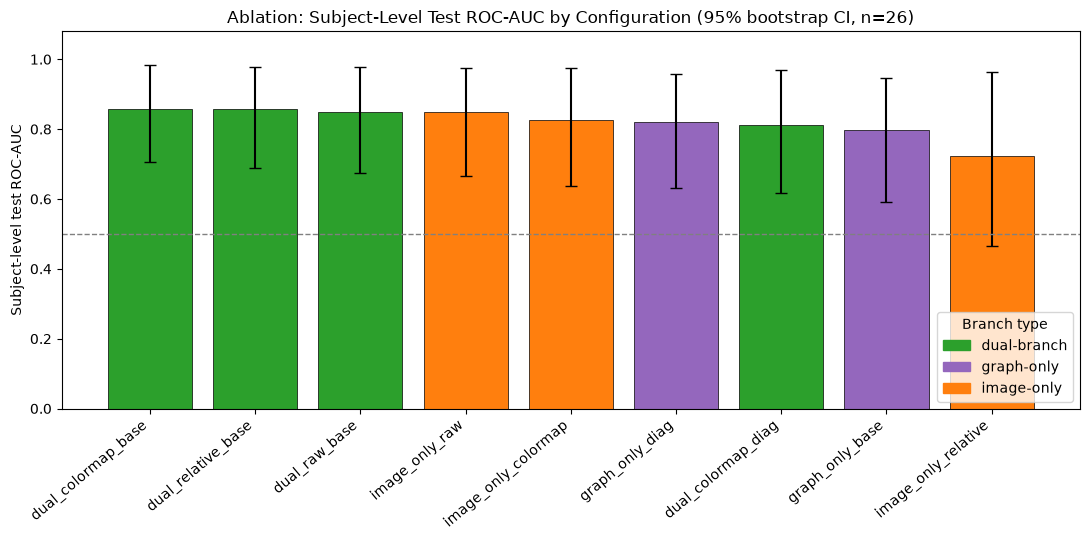

In [17]:
fig, ax = plt.subplots(figsize=(11, 5.5))

yerr_low = (plot_df["test_roc_auc_subject"] - plot_df["test_roc_auc_subject_ci_low"]).clip(lower=0)
yerr_high = (plot_df["test_roc_auc_subject_ci_high"] - plot_df["test_roc_auc_subject"]).clip(lower=0)

ax.bar(plot_df["config_name"], plot_df["test_roc_auc_subject"], color=colors,
       yerr=[yerr_low, yerr_high], capsize=4, edgecolor="black", linewidth=0.5)
ax.set_ylabel("Subject-level test ROC-AUC")
ax.set_title("Ablation: Subject-Level Test ROC-AUC by Configuration (95% bootstrap CI, n=26)")
ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels(plot_df["config_name"], rotation=40, ha="right")
ax.set_ylim(0, 1.08)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Chance")

legend_handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in BRANCH_COLORS.values()]
ax.legend(legend_handles, list(BRANCH_COLORS.keys()), title="Branch type", loc="lower right")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "ablation_roc_auc_comparison.png", dpi=150)
plt.show()

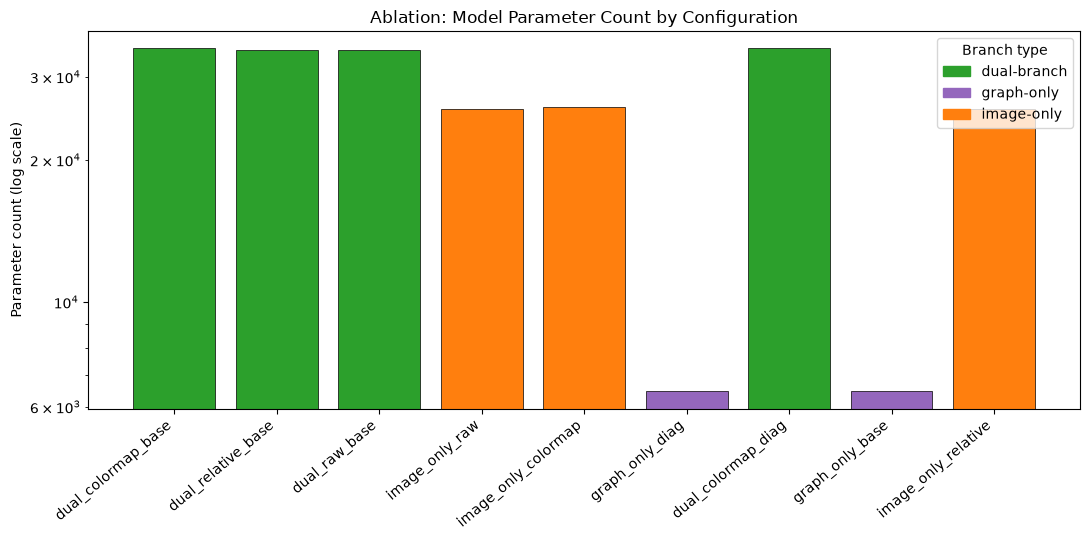

In [18]:
fig, ax = plt.subplots(figsize=(11, 5.5))

ax.bar(plot_df["config_name"], plot_df["param_count"], color=colors, edgecolor="black", linewidth=0.5)
ax.set_yscale("log")
ax.set_ylabel("Parameter count (log scale)")
ax.set_title("Ablation: Model Parameter Count by Configuration")
ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels(plot_df["config_name"], rotation=40, ha="right")

legend_handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in BRANCH_COLORS.values()]
ax.legend(legend_handles, list(BRANCH_COLORS.keys()), title="Branch type", loc="upper right")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "ablation_param_count_comparison.png", dpi=150)
plt.show()

## Section 9 — Qualitative Summary (fill in after reviewing Section 7's printed table)

Interpreting statistical meaningfulness from one run's small-sample (n=26 test subjects)
numbers is a judgment call worth making deliberately — not something to auto-generate as a
confident-sounding claim. Review the printed Section 7 table and Section 6 CIs above, then
fill in each answer below.

**Q1. Does the dual-branch architecture outperform *both* single-branch ablations
(graph-only, image-only)?**
- Answer from the results table: _(fill in)_
- Is the gap large relative to the bootstrap CIs from Section 6, or within noise for a test
  set this small? _(fill in)_

**Q2. Does colormap outperform raw/relative as the image source?**
- Answer from the results table: _(fill in)_
- Large relative to the CIs, or within noise? _(fill in)_

**Q3. Does the diagonal-adjacency graph topology (deferred back in Phase 6) outperform the
base 4-cycle — or was that extra complexity not worth it?**
- Answer from the results table: _(fill in)_
- Large relative to the CIs, or within noise? _(fill in)_

*(Left intentionally blank for review of this specific run's actual numbers.)*

## Section 10 — Save Results

Three output files to `results/`:

1. `ablation_results.csv` — the Section 7 summary table (9 rows).
2. `ablation_test_predictions.csv` — the Section 5 combined long-format per-sample predictions
   across all 9 configs, both foot-level and subject-level rows (`level` column distinguishes
   them).
3. `ablation_summary.json` — the config list, hyperparameters used, bootstrap CI method/seed,
   and the full results table as a dict.

In [19]:
print("=== SECTION 10: Save Results ===")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ablation_results_path = RESULTS_DIR / "ablation_results.csv"
ablation_results_df.to_csv(ablation_results_path, index=False)
print(f"Saved {ablation_results_path}  -- shape {ablation_results_df.shape}")

ablation_predictions_path = RESULTS_DIR / "ablation_test_predictions.csv"
ablation_test_predictions_df.to_csv(ablation_predictions_path, index=False)
print(f"Saved {ablation_predictions_path}  -- shape {ablation_test_predictions_df.shape}")

=== SECTION 10: Save Results ===
Saved c:\workstation\3RD YEAR\Diabetic_Foot\results\ablation_results.csv  -- shape (9, 14)
Saved c:\workstation\3RD YEAR\Diabetic_Foot\results\ablation_test_predictions.csv  -- shape (702, 8)


In [20]:
ablation_summary = {
    "ablation_configs": ABLATION_CONFIGS,
    "hyperparameters": {
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "lr": LR,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": 16,
        "class_weights": {
            "weight_control": weight_control,
            "weight_dm": weight_dm,
            "pos_weight_used": "weight_dm",
        },
    },
    "mc_dropout_T": T_MC,
    "bootstrap_ci": {
        "method": "subject-level nonparametric bootstrap, 1000 resamples with replacement, "
                  "same resample index matrix reused across all 9 configs for a paired comparison",
        "n_boot": N_BOOT,
        "seed": BOOT_SEED,
        "percentiles": [2.5, 97.5],
    },
    "primary_row_source": (
        "Primary config's reported test_roc_auc_foot / test_roc_auc_subject / "
        "test_balanced_accuracy_subject / test_f1_subject / optimal_threshold are reused "
        "verbatim from results/test_evaluation_summary.json (Phase 11), not recomputed here. "
        "The bootstrap CI, combined predictions file, and plots use this notebook's own fresh "
        "MC-Dropout recomputation for the primary config, run through the identical Section 5 "
        "code path as the other 8 configs."
    ),
    "checkpoints_used": {
        c["name"]: (
            str(CHECKPOINT_DIR / "primary_model_best.pt") if c["name"] == PRIMARY_CONFIG_NAME
            else str(CHECKPOINT_DIR / f"ablation_{c['name']}_best.pt")
        )
        for c in ABLATION_CONFIGS
    },
    "results_table": ablation_results_df.to_dict(orient="records"),
}

ablation_summary_path = RESULTS_DIR / "ablation_summary.json"
with open(ablation_summary_path, "w") as f:
    json.dump(ablation_summary, f, indent=2, default=float)

print(f"Saved {ablation_summary_path}")

Saved c:\workstation\3RD YEAR\Diabetic_Foot\results\ablation_summary.json


## Section 11 — Final Summary

In [21]:
print("=" * 78)
print("=== SECTION 11: FINAL SUMMARY ===")
print("=" * 78)

print("\nFull ranked ablation results table (sorted by subject-level test ROC-AUC):\n")
print(ablation_results_df.to_string(index=False))

top_row = ablation_results_df.iloc[0]
print(f"\nTop performer: {top_row['config_name']}")
print(f"  subject-level test ROC-AUC = {top_row['test_roc_auc_subject']:.4f}  "
      f"95% CI [{top_row['test_roc_auc_subject_ci_low']:.4f}, {top_row['test_roc_auc_subject_ci_high']:.4f}]")

if len(ablation_results_df) > 1:
    runner_up_row = ablation_results_df.iloc[1]
    margin = top_row["test_roc_auc_subject"] - runner_up_row["test_roc_auc_subject"]
    ci_overlap = not (
        top_row["test_roc_auc_subject_ci_low"] > runner_up_row["test_roc_auc_subject_ci_high"]
        or runner_up_row["test_roc_auc_subject_ci_low"] > top_row["test_roc_auc_subject_ci_high"]
    )
    print(f"  margin over runner-up ({runner_up_row['config_name']}): {margin:.4f}")
    print(f"  bootstrap CIs overlap with runner-up: {ci_overlap}  "
          f"({'not clearly distinguishable at this sample size' if ci_overlap else 'CIs do not overlap'})")

print(f"\nAll {len(ABLATION_CONFIGS)} configs were evaluated through an identical Section 5 "
      f"procedure in this same notebook run (own val threshold, own MC-Dropout T={T_MC} test "
      f"pass, own foot- and subject-level metrics, own bootstrap CI). The primary config's "
      f"REPORTED numbers in the table above were substituted with Phase 11's already-computed "
      f"results/test_evaluation_summary.json values per the task spec, rather than this "
      f"notebook's fresh recomputation -- see Section 5/7 markdown for why.")

print("\nSaved result files:")
for p in [ablation_results_path, ablation_predictions_path, ablation_summary_path]:
    print(f"  - {p}  (exists: {p.exists()})")

issues_found = []
for name, res in per_config_results.items():
    if res.get("n_boot_skipped", 0) > 0:
        issues_found.append(
            f"{name}: {res['n_boot_skipped']}/{N_BOOT} bootstrap resamples were skipped "
            f"(single-class resample, ROC-AUC undefined) -- CI computed from the remaining "
            f"{res['n_boot_used']} resamples."
        )

print()
if len(issues_found) == 0:
    print("Issues found: 0 issues found.")
else:
    print(f"Issues found ({len(issues_found)}):")
    for issue in issues_found:
        print(f"  - {issue}")

print("\n" + "=" * 78)
print("=== TEST SET ACCESS NOTICE (REPEATED) " + "=" * 39)
print("=" * 78)
print(TEST_SET_NOTICE)
print("=" * 78)

=== SECTION 11: FINAL SUMMARY ===

Full ranked ablation results table (sorted by subject-level test ROC-AUC):

        config_name  use_graph_branch  use_image_branch graph_topology      image_key  param_count  best_val_roc_auc  test_roc_auc_foot  test_roc_auc_subject  test_roc_auc_subject_ci_low  test_roc_auc_subject_ci_high  test_balanced_accuracy_subject  test_f1_subject  optimal_threshold
 dual_colormap_base              True              True           base colormap_image        34433          0.940476           0.836466              0.857143                     0.706580                      0.984962                        0.680451         0.810811           0.610355
 dual_relative_base              True              True           base relative_image        34145          0.942460           0.821429              0.857143                     0.687500                      0.977530                        0.680451         0.810811           0.664434
      dual_raw_base              T

---

## 🔒 REMINDER: TEST SET TOUCHED FOR THE SECOND AND FINAL TIME 🔒

No further test-set access should occur for the rest of this project. Any future architectural
or hyperparameter changes must be validated on train/val only.